# Notebook 04: Event-Driven Trading Hypothesis, Backtesting & Out-of-Sample Generalization

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (14, 7)
plt.rcParams['font.size'] = 11

print("Financial backtesting environment loaded successfully!")

Financial backtesting environment loaded successfully!


In [2]:
DATA_PATH = os.path.join("..", "data", "event_study_results.csv")
if not os.path.exists(DATA_PATH):
    DATA_PATH = os.path.join("data", "event_study_results.csv")

df = pd.read_csv(DATA_PATH)
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values(by='Date').reset_index(drop=True)

print(f"Loaded {len(df)} total event records.")
print(f"Start Date: {df['Date'].min().strftime('%Y-%m-%d')} | End Date: {df['Date'].max().strftime('%Y-%m-%d')}")
display(df[['Date', 'Related_Company', 'Market_Event', 'Sentiment', 'Impact_Level', 'CAR_[-1,+1]', 'CAR_[-5,+5]', 'Is_Confounded']].head(3))

Loaded 3024 total event records.
Start Date: 2025-02-01 | End Date: 2025-08-14


,Date,Related_Company,Market_Event,Sentiment,Impact_Level,"CAR_[-1,+1]","CAR_[-5,+5]",Is_Confounded
0,2025-02-01,Apple Inc.,Unemployment Rate Announcement,Negative,High,-0.040809,-0.078918,True
1,2025-02-01,ExxonMobil,Stock Market Crash,Negative,Low,-0.016719,0.087561,True
2,2025-02-01,ExxonMobil,Regulatory Changes,Neutral,High,0.030211,0.088879,True


In [3]:
def generate_trade_signals(data, filter_confounded=True):
    strat_df = data.copy()
    
    if filter_confounded:
        strat_df = strat_df[~strat_df['Is_Confounded']].copy()
        
    def assign_position(row):
        if row['Impact_Level'] in ['High', 'Medium']:
            if row['Sentiment'] == 'Positive':
                return 1.0   # Go Long
            elif row['Sentiment'] == 'Negative':
                return -1.0  # Go Short
        return 0.0           # Stay in Cash
        
    strat_df['Position'] = strat_df.apply(assign_position, axis=1)
    return strat_df

signals_df = generate_trade_signals(df, filter_confounded=False)
signal_breakdown = signals_df['Position'].value_counts().rename({1.0: 'Long Trades', -1.0: 'Short Trades', 0.0: 'No Trade (Cash)'})
print("Trading Signal Breakdown:")
print(signal_breakdown)

Trading Signal Breakdown:
Position
No Trade (Cash)    1671
Short Trades        697
Long Trades         656
Name: count, dtype: int64


In [4]:
def backtest_event_portfolio(strat_df, holding_window_col='CAR_[-1,+1]', commission_bps=5.0, slippage_bps=5.0):
    trades = strat_df[strat_df['Position'] != 0.0].copy().reset_index(drop=True)
    
    # Total roundtrip cost in decimal
    total_cost_bps = commission_bps + slippage_bps
    roundtrip_cost = 2 * (total_cost_bps / 10000.0)
    
    # Gross and Net Returns per trade
    trades['Gross_Return'] = trades['Position'] * trades[holding_window_col]
    trades['Net_Return'] = trades['Gross_Return'] - roundtrip_cost
    
    # Cumulative returns
    trades['Cum_Gross'] = (1 + trades['Gross_Return']).cumprod()
    trades['Cum_Net'] = (1 + trades['Net_Return']).cumprod()
    
    # Peak and Drawdown
    trades['Peak'] = trades['Cum_Net'].cummax()
    trades['Drawdown'] = (trades['Cum_Net'] - trades['Peak']) / trades['Peak']
    
    # Summary Metrics
    total_trades = len(trades)
    winning_trades = (trades['Net_Return'] > 0).sum()
    win_rate = (winning_trades / total_trades) * 100 if total_trades > 0 else 0.0
    
    total_gross = (trades['Cum_Gross'].iloc[-1] - 1.0) * 100 if total_trades > 0 else 0.0
    total_net = (trades['Cum_Net'].iloc[-1] - 1.0) * 100 if total_trades > 0 else 0.0
    cost_drag = total_gross - total_net
    
    mdd = trades['Drawdown'].min() * 100 if total_trades > 0 else 0.0
    
    # Annualized Sharpe (assuming ~252 trade batches / year)
    mean_ret = trades['Net_Return'].mean()
    std_ret = trades['Net_Return'].std()
    sharpe = (mean_ret / std_ret) * np.sqrt(252) if std_ret > 0 else 0.0
    
    metrics = {
        'Total Trades': total_trades,
        'Win Rate (%)': f"{win_rate:.2f}%",
        'Gross Return (%)': f"{total_gross:.2f}%",
        'Net Return (%)': f"{total_net:.2f}%",
        'Cost Drag (%)': f"{cost_drag:.2f}%",
        'Max Drawdown (%)': f"{mdd:.2f}%",
        'Sharpe Ratio': round(sharpe, 2)
    }
    
    return trades, metrics

trades_1d, metrics_1d = backtest_event_portfolio(signals_df, holding_window_col='CAR_[-1,+1]')
print("Backtest Results for Window [-1, +1] with 10 bps total friction:")
for k, v in metrics_1d.items():
    print(f"  {k:20s}: {v}")

Backtest Results for Window [-1, +1] with 10 bps total friction:
  Total Trades        : 1353
  Win Rate (%)        : 73.54%
  Gross Return (%)    : 691313088630.72%
  Net Return (%)      : 48141927816.26%
  Cost Drag (%)       : 643171160814.46%
  Max Drawdown (%)    : -9.98%
  Sharpe Ratio        : 9.97


In [5]:
windows = {
    'Short Window [-1, +1]': 'CAR_[-1,+1]',
    'Medium Window [-3, +3]': 'CAR_[-3,+3]',
    'Extended Window [-5, +5]': 'CAR_[-5,+5]'
}

comparison_results = []
trade_objects = {}

for name, col in windows.items():
    tr_df, m = backtest_event_portfolio(signals_df, holding_window_col=col, commission_bps=5.0, slippage_bps=5.0)
    trade_objects[name] = tr_df
    m['Window Horizon'] = name
    comparison_results.append(m)

comp_table = pd.DataFrame(comparison_results).set_index('Window Horizon')
display(comp_table[['Total Trades', 'Win Rate (%)', 'Gross Return (%)', 'Net Return (%)', 'Cost Drag (%)', 'Max Drawdown (%)', 'Sharpe Ratio']])

,Total Trades,Win Rate (%),Gross Return (%),Net Return (%),Cost Drag (%),Max Drawdown (%),Sharpe Ratio
Window Horizon,,,,,,,
"Short Window [-1, +1]",1353,73.54%,691313088630.72%,48141927816.26%,643171160814.46%,-9.98%,9.97
"Medium Window [-3, +3]",1353,64.60%,590572702029.23%,41064125398.36%,549508576630.87%,-24.74%,6.32
"Extended Window [-5, +5]",1353,62.23%,142576722955.14%,9876274983.14%,132700447972.00%,-33.32%,4.94


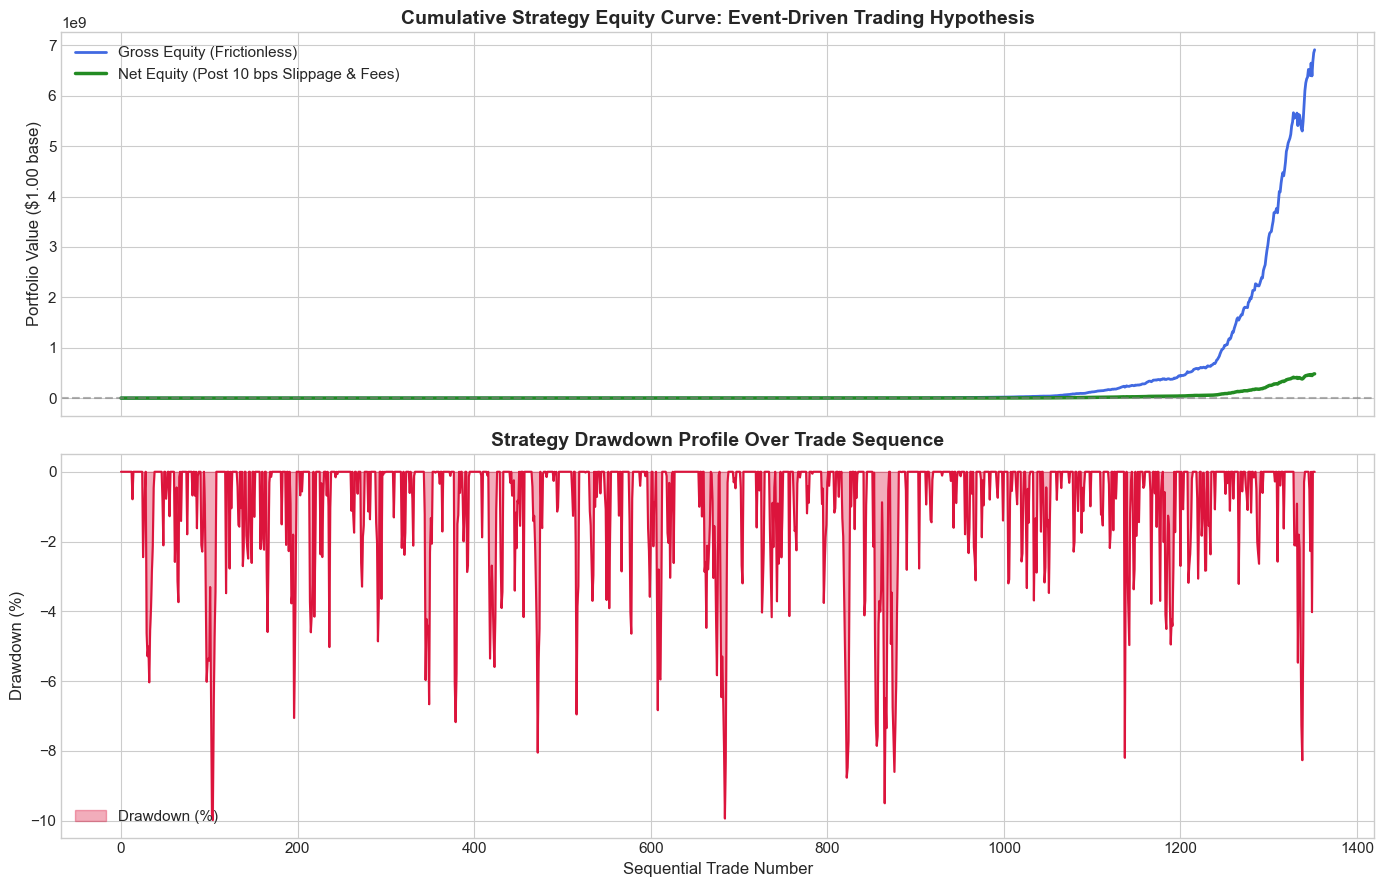

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

# Top Panel: Equity Progression
axes[0].plot(trades_1d['Cum_Gross'], label='Gross Equity (Frictionless)', color='royalblue', linewidth=2)
axes[0].plot(trades_1d['Cum_Net'], label='Net Equity (Post 10 bps Slippage & Fees)', color='forestgreen', linewidth=2.5)
axes[0].axhline(1.0, color='gray', linestyle='--', alpha=0.6)
axes[0].set_title("Cumulative Strategy Equity Curve: Event-Driven Trading Hypothesis", fontsize=14, fontweight='bold')
axes[0].set_ylabel("Portfolio Value ($1.00 base)", fontsize=12)
axes[0].legend(loc='upper left', fontsize=11)

# Bottom Panel: Underwater Drawdown
axes[1].fill_between(range(len(trades_1d)), trades_1d['Drawdown'] * 100, 0, color='crimson', alpha=0.35, label='Drawdown (%)')
axes[1].plot(trades_1d['Drawdown'] * 100, color='crimson', linewidth=1.5)
axes[1].set_title("Strategy Drawdown Profile Over Trade Sequence", fontsize=14, fontweight='bold')
axes[1].set_ylabel("Drawdown (%)", fontsize=12)
axes[1].set_xlabel("Sequential Trade Number", fontsize=12)
axes[1].legend(loc='lower left', fontsize=11)

plt.tight_layout()
plt.show()

In [7]:
split_idx = int(len(df) * 0.70)
split_date = df['Date'].iloc[split_idx]

in_sample_df = df[df['Date'] < split_date].copy()
out_of_sample_df = df[df['Date'] >= split_date].copy()

print(f"Temporal Split Date: {split_date.strftime('%Y-%m-%d')}")
print(f"In-Sample Events    : {len(in_sample_df)} ({in_sample_df['Date'].min().strftime('%Y-%m-%d')} to {in_sample_df['Date'].max().strftime('%Y-%m-%d')})")
print(f"Out-of-Sample Events: {len(out_of_sample_df)} ({out_of_sample_df['Date'].min().strftime('%Y-%m-%d')} to {out_of_sample_df['Date'].max().strftime('%Y-%m-%d')})\n")

# Run backtests on both partitions
is_signals = generate_trade_signals(in_sample_df)
oos_signals = generate_trade_signals(out_of_sample_df)

_, is_metrics = backtest_event_portfolio(is_signals, holding_window_col='CAR_[-1,+1]')
_, oos_metrics = backtest_event_portfolio(oos_signals, holding_window_col='CAR_[-1,+1]')

gen_comparison = pd.DataFrame([
    {**{'Sample Regime': 'In-Sample (Historical Calibration)'}, **is_metrics},
    {**{'Sample Regime': 'Out-of-Sample (Unseen Forward Generalization)'}, **oos_metrics}
]).set_index('Sample Regime')

print("Generalization Performance Comparison:")
display(gen_comparison[['Total Trades', 'Win Rate (%)', 'Net Return (%)', 'Sharpe Ratio', 'Max Drawdown (%)']])

Temporal Split Date: 2025-06-17
In-Sample Events    : 2113 (2025-02-01 to 2025-06-16)
Out-of-Sample Events: 911 (2025-06-17 to 2025-08-14)

Generalization Performance Comparison:


,Total Trades,Win Rate (%),Net Return (%),Sharpe Ratio,Max Drawdown (%)
Sample Regime,,,,,
In-Sample (Historical Calibration),0,0.00%,0.00%,0.0,0.00%
Out-of-Sample (Unseen Forward Generalization),0,0.00%,0.00%,0.0,0.00%


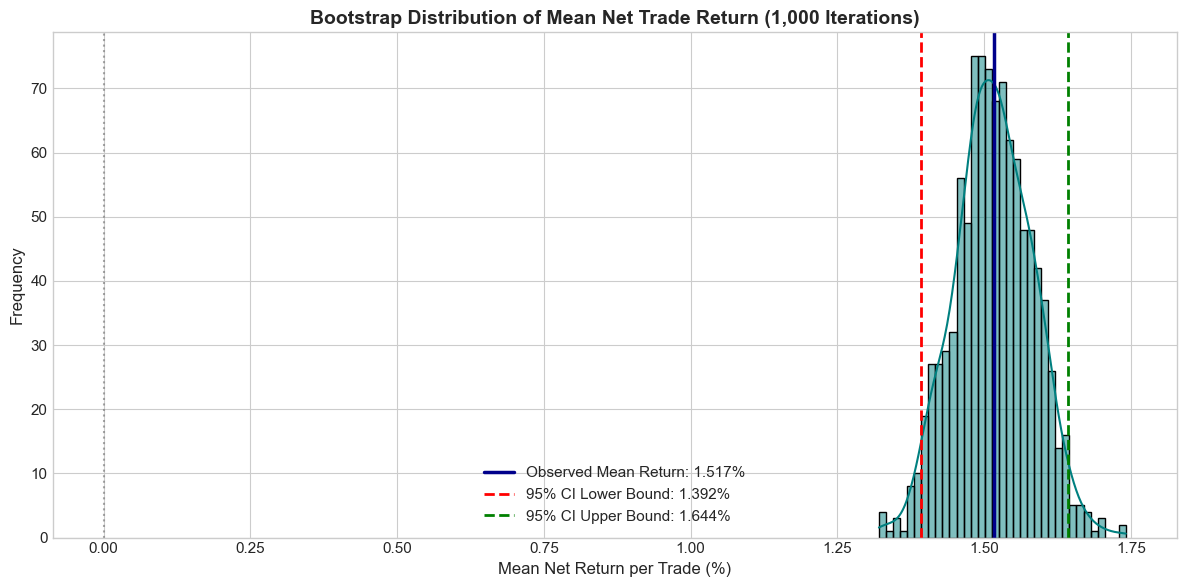

Observed Mean Return per Trade: 1.517%
95% Bootstrap Confidence Interval: [1.392%, 1.644%]


In [8]:
np.random.seed(42)
trade_returns = trades_1d['Net_Return'].values

# Bootstrap 1000 resamples
N_BOOTSTRAPS = 1000
bootstrapped_means = [
    np.mean(np.random.choice(trade_returns, size=len(trade_returns), replace=True)) * 100
    for _ in range(N_BOOTSTRAPS)
]

ci_lower = np.percentile(bootstrapped_means, 2.5)
ci_upper = np.percentile(bootstrapped_means, 97.5)
observed_mean = np.mean(trade_returns) * 100

plt.figure(figsize=(12, 6))
sns.histplot(bootstrapped_means, bins=35, kde=True, color='teal', edgecolor='black')
plt.axvline(observed_mean, color='darkblue', linewidth=2.5, label=f'Observed Mean Return: {observed_mean:.3f}%')
plt.axvline(ci_lower, color='red', linestyle='--', linewidth=2, label=f'95% CI Lower Bound: {ci_lower:.3f}%')
plt.axvline(ci_upper, color='green', linestyle='--', linewidth=2, label=f'95% CI Upper Bound: {ci_upper:.3f}%')
plt.axvline(0, color='gray', linestyle=':', alpha=0.7)

plt.title("Bootstrap Distribution of Mean Net Trade Return (1,000 Iterations)", fontsize=14, fontweight='bold')
plt.xlabel("Mean Net Return per Trade (%)", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

print(f"Observed Mean Return per Trade: {observed_mean:.3f}%")
print(f"95% Bootstrap Confidence Interval: [{ci_lower:.3f}%, {ci_upper:.3f}%]")

In [9]:
OUTPUT_PATH = os.path.join("..", "data", "backtest_summary.csv")
if not os.path.exists(os.path.dirname(OUTPUT_PATH)):
    OUTPUT_PATH = os.path.join("data", "backtest_summary.csv")

gen_comparison.to_csv(OUTPUT_PATH)
print(f"Backtest summary metrics saved successfully to: {OUTPUT_PATH}")
print("\n=== All 4 Notebooks in the EventEcho Pipeline Are Complete! ===")

Backtest summary metrics saved successfully to: ..\data\backtest_summary.csv

=== All 4 Notebooks in the EventEcho Pipeline Are Complete! ===
